# Image denoising with DFT matrices on CIM

Remove periodic stripe interference from a real grayscale photograph using a discrete Fourier transform (DFT), a two-bin notch mask, and an inverse DFT. No neural network or training is involved. Compare NumPy's FFT implementation with real matrix multiplications mapped onto MemFast arrays, first with ideal devices and then with write variation of 0.05.

The executed results and full-size figure are retained below. Install MemFast in this Python environment, plus `numpy`, `Pillow`, `matplotlib`, and a Jupyter frontend to rerun the notebook. The lake landscape is included in `assets/lake_landscape.png`; no image download is needed. Run all cells in order. The image is 256 x 256; CUDA is selected when available, with CPU as the fallback.

In [1]:
%matplotlib inline
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

from memfast import Config, Nonidealities, Simulator

DEVICE = os.environ.get("MEMFAST_NOTEBOOK_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
SIZE = 256
SEED = 135
STRIPE_AMPLITUDE = 0.18
STRIPE_CYCLES = 12  # Known interference frequency: cycles across the image width.
print(f"Device: {DEVICE}; image: {SIZE} x {SIZE}")

Device: cuda:0; image: 256 x 256


## 1. Load the photograph and add noise

Load the bundled lake landscape, convert it to grayscale and add vertical stripes: $n(y,x)=0.18\cos(2\pi\,12x/256)$. This models additive periodic interference at a known frequency. Preserve values outside [0, 1] during processing: clipping the input would create additional harmonics. Only the displayed input is clipped. The resized photograph is the clean target for PSNR; it is never an input to the denoiser.

Image: [Lake Mapourika](https://commons.wikimedia.org/wiki/File:Lake_Mapourika1.jpg), Paul Stewart, [CC0 1.0](https://creativecommons.org/publicdomain/zero/1.0/). The bundled image is a square crop resized from the original photograph.

In [2]:
notebook_dir = Path.cwd()
if not (notebook_dir / "03_dft_image_denoising.ipynb").is_file():
    notebook_dir = notebook_dir / "examples" / "notebooks"
sample_path = notebook_dir / "assets" / "lake_landscape.png"
with Image.open(sample_path) as photograph:
    grayscale = photograph.convert("L").resize((SIZE, SIZE), resample=Image.Resampling.LANCZOS)
    clean = np.asarray(grayscale, dtype=np.float64) / 255.0
columns = np.arange(SIZE)[None, :]
interference = STRIPE_AMPLITUDE * np.cos(2 * np.pi * STRIPE_CYCLES * columns / SIZE)
noisy = clean + interference
offset = float(noisy.mean())
centered = noisy - offset
assert clean.shape == noisy.shape == (SIZE, SIZE)
assert np.isfinite(clean).all() and np.isfinite(noisy).all()
print(f"Clean range: [{clean.min():.3f}, {clean.max():.3f}]")

Clean range: [0.000, 1.000]


## 2. Define the normalized DFT and the frequency mask

For an $N \times N$ image $X$, define the unitary DFT matrix

$$F_{k,n} = \frac{1}{\sqrt{N}}\exp\left(-2\pi i\frac{kn}{N}\right).$$

The two-dimensional transform and inverse are

$$Y = F X F^T, \qquad \widehat{X} = F^H (M \odot Y)\,\overline{F}.$$

Here $T$ means transpose, $H$ means conjugate transpose, and the bar means complex conjugation. Each axis uses the $1/\sqrt{N}$ normalization, matching NumPy's `norm='ortho'` in both directions.

A sinusoid constant along the vertical axis occupies two conjugate bins: $(0,12)$ and $(0,N-12)$. Set only these mask entries to zero and leave all other frequencies unchanged.

$$M[k_y,k_x]=\begin{cases}0 & k_y=0,\ k_x\in\{12,N-12\},\\1 & \text{otherwise}.\end{cases}$$

Unlike a low-pass filter, this mask preserves detail at the other frequencies. It also removes any genuine image content at the two selected bins, so even the floating-point reconstruction need not exactly equal the original. The notch frequency comes from the known interference, without tuning against the clean image. This example targets periodic interference rather than arbitrary noise.

Subtract the observed image mean before the transforms and add it back after the inverse. This digital DC bypass reduces the dynamic range seen by the 8-bit quantizers; it uses no clean-image information. The DC mask entry remains one. NumPy and CIM use the same centering and mask.

In [3]:
indices = np.arange(SIZE)
F = np.exp(-2j * np.pi * np.outer(indices, indices) / SIZE) / np.sqrt(SIZE)
mask = np.ones((SIZE, SIZE))
mask[0, STRIPE_CYCLES] = mask[0, -STRIPE_CYCLES] = 0.0

numpy_spectrum = np.fft.fft2(centered, norm="ortho")
numpy_inverse = np.fft.ifft2(mask * numpy_spectrum, norm="ortho")
standard = np.clip(numpy_inverse.real + offset, 0.0, 1.0)

# Verify signs, normalization, both axes, and the inverse independently.
np.testing.assert_allclose(F @ centered @ F.T, numpy_spectrum, atol=1e-12, rtol=1e-12)
np.testing.assert_allclose(F.conj().T @ numpy_spectrum @ F.conj(), centered, atol=1e-12, rtol=1e-12)
assert mask[0, 0] == 1.0 and np.count_nonzero(mask == 0) == 2
print(f"Notches: (0, {STRIPE_CYCLES}) and (0, {SIZE - STRIPE_CYCLES})")
print(f"Frequencies retained: {np.count_nonzero(mask)} / {mask.size}")
print(f"NumPy inverse imaginary RMS: {np.sqrt(np.mean(numpy_inverse.imag**2)):.3e}")

Notches: (0, 12) and (0, 244)
Frequencies retained: 65534 / 65536
NumPy inverse imaginary RMS: 4.536e-17


## 3. Set ideal and write-variation configurations

Both runs use signed 8-bit inputs and weights, binary slices, 64 x 64 arrays, and 8-bit ADCs. A 256 x 256 DFT matrix spans multiple arrays: each ADC converts at most 64 rows, then digital accumulation restores the scale of each partial sum. Each binary-slice count lies within the ADC's 0..255 range for ideal devices. Weight scales are per output channel; input scales are per row and per group of 64 values, matching the rows accumulated before each ADC conversion.

**Ideal devices still quantize.** Compare them with a dequantized matrix-product oracle, not with an assumption of exact floating-point DFT output. The ideal case explicitly sets write variation to zero; the second enables only write variation of 0.05. Read variation and other nonidealities remain zero. Each programmed cell has a fixed multiplicative conductance perturbation $G'=G\exp(0.05\epsilon)$, with $\epsilon\sim\mathcal{N}(0,1)$. Real and imaginary forward/inverse maps are programmed separately. The seed and matrix creation order make programming reproducible.

In [4]:
common = dict(
    activation_bits=8,
    weight_bits=8,
    input_slice=(1,) * 8,
    weight_slice=(1,) * 8,
    array_size=(64, 64),
    adc_bits=8,
    input_quant_gran=(1, 64),
    weight_quant_gran=(None, 1),
    seed=SEED,
)
ideal_config = Config(**common, nonidealities=Nonidealities(write_variation=0.0))
write_config = Config(**common, nonidealities=Nonidealities(write_variation=0.05))
print("Ideal:", ideal_config.nonidealities)
print("Write 0.05:", write_config.nonidealities)

Ideal: Nonidealities(write_variation=0.0, read_variation=0.0, read_mode='shared', voltage_variation=0.0, adc_nonlinearity=0.0, stuck_at_low=0.0, stuck_at_high=0.0, drift_coefficient=0.0, drift_time=0.0, drift_reference_time=1.0)
Write 0.05: Nonidealities(write_variation=0.05, read_variation=0.0, read_mode='shared', voltage_variation=0.0, adc_nonlinearity=0.0, stuck_at_low=0.0, stuck_at_high=0.0, drift_coefficient=0.0, drift_time=0.0, drift_reference_time=1.0)


## 4. Express complex transforms as real matrix multiplications

For a complex right-hand matrix $B=C+iD$ and row vectors $z=a+ib$,

$$zB=(aC-bD)+i(aD+bC).$$

Use `simulator.matmul(A, B)` with the same operand order as `torch.matmul`.
No programming call or matrix name is required: the simulator manages its
programmed weights internally. Move the selected image axis to the last
dimension so each row is one transform input.

The DFT matrix is symmetric. The right-hand matrix for a forward axis transform
is therefore $F^T=F$, and for an inverse axis transform it is
$\overline F$. All forward and inverse products below pass through MemFast.
Complex assembly, DC bypass, frequency masking, axis movement and clipping are digital;
NumPy FFT appears only in the reference.

In [5]:
def complex_weights(basis, device):
    real = torch.tensor(basis.real, dtype=torch.float32, device=device)
    imag = torch.tensor(basis.imag, dtype=torch.float32, device=device)
    return real, imag


def transform_axis(values, weights, axis, simulator):
    real_weight, imag_weight = weights
    real = values.real.movedim(axis, -1).contiguous()
    imag = values.imag.movedim(axis, -1).contiguous()
    transformed = torch.complex(
        simulator.matmul(real, real_weight) - simulator.matmul(imag, imag_weight),
        simulator.matmul(imag, real_weight) + simulator.matmul(real, imag_weight),
    )
    return transformed.movedim(-1, axis)


@torch.no_grad()
def cim_denoise(image, frequency_mask, config, device="cpu"):
    image = np.asarray(image, dtype=np.float64)
    assert image.ndim == 2 and image.shape[0] == image.shape[1]
    assert frequency_mask.shape == image.shape
    assert np.isfinite(image).all() and np.isfinite(frequency_mask).all()
    n = image.shape[0]
    coordinates = np.arange(n)
    basis = np.exp(-2j * np.pi * np.outer(coordinates, coordinates) / n) / np.sqrt(n)
    simulator = Simulator(config, device=device)
    forward_weights = complex_weights(basis, simulator.device)
    inverse_weights = complex_weights(basis.conj(), simulator.device)
    pixels = torch.tensor(image, dtype=torch.float32, device=simulator.device)
    values = torch.complex(pixels, torch.zeros_like(pixels))
    spectrum = transform_axis(
        transform_axis(values, forward_weights, axis=1, simulator=simulator),
        forward_weights,
        axis=0,
        simulator=simulator,
    )
    filtered = spectrum * torch.tensor(frequency_mask, dtype=torch.float32, device=simulator.device)
    restored = transform_axis(
        transform_axis(filtered, inverse_weights, axis=1, simulator=simulator),
        inverse_weights,
        axis=0,
        simulator=simulator,
    )
    return spectrum.cpu().numpy(), restored.cpu().numpy()

## 5. Check the mapping and compare PSNR

The ideal-device check below quantizes and dequantizes signed test vectors and one real DFT matrix, then compares their digital product with a CIM read.

Use $\mathrm{PSNR}=10\log_{10}(1/\mathrm{MSE})$, with peak intensity one and MSE measured against the clean image. The noisy-input PSNR uses the original, unclipped measurements; its display is clipped to [0, 1]. Take the real part, restore the image mean and clip each reconstruction identically before PSNR and display. Use float64 differences and floor MSE at the smallest positive normal float64 value. Also report imaginary RMS before projection: quantization and separately programmed real/imaginary maps can break conjugate symmetry.

`diagnostic(device='cpu')` returns reconstructed images and PSNR measurements after the preceding cells have run.

In [6]:
def psnr(target, estimate):
    target = np.asarray(target, dtype=np.float64)
    estimate = np.asarray(estimate, dtype=np.float64)
    assert target.shape == estimate.shape
    assert np.isfinite(target).all() and np.isfinite(estimate).all()
    mse = np.mean(np.square(target - estimate))
    return float(-10.0 * np.log10(max(float(mse), np.finfo(np.float64).tiny)))


def diagnostic(device="cpu"):
    simulator = Simulator(ideal_config, device=device)
    weight = torch.tensor(F.real, dtype=torch.float32, device=simulator.device)
    vectors = torch.linspace(-1, 1, 3 * SIZE, device=simulator.device).reshape(3, SIZE)
    weight_scale = weight.abs().amax(dim=0, keepdim=True) / 127
    groups = vectors.reshape(3, SIZE // 64, 64)
    input_scale = (groups.abs().amax(dim=-1, keepdim=True) / 127).expand_as(groups).reshape_as(vectors)
    dequant_weight = (weight / weight_scale).round().clamp(-127, 127) * weight_scale
    dequant_input = (vectors / input_scale).round().clamp(-127, 127) * input_scale
    expected = dequant_input @ dequant_weight
    actual = simulator.mm(vectors, weight)
    torch.testing.assert_close(actual, expected, rtol=1e-5, atol=2e-5)
    print(f"Ideal dequantized product max error: {(actual - expected).abs().max().item():.3e}")

    results = {
        "Noisy": {"image": noisy, "psnr_db": psnr(clean, noisy)},
        "NumPy notch": {"image": standard, "psnr_db": psnr(clean, standard)},
    }
    for label, config in [("CIM ideal", ideal_config), ("CIM write 0.05", write_config)]:
        spectrum, raw = cim_denoise(centered, mask, config, device=device)
        assert raw.shape == clean.shape and np.isfinite(raw).all()
        image = np.clip(raw.real + offset, 0.0, 1.0)
        results[label] = dict(
            image=image,
            psnr_db=psnr(clean, image),
            imaginary_rms=float(np.sqrt(np.mean(raw.imag.astype(np.float64) ** 2))),
            rmse_vs_numpy=float(np.sqrt(np.mean((image - standard) ** 2))),
            spectrum_relative_error=float(
                np.linalg.norm(spectrum - numpy_spectrum) / np.linalg.norm(numpy_spectrum)
            ),
        )
    assert all(np.isfinite(item["psnr_db"]) for item in results.values())
    assert results["CIM ideal"]["rmse_vs_numpy"] < 0.03
    return results


results = diagnostic(device=DEVICE)
print(f"\n{'Method':<20} {'PSNR (dB)':>12} {'RMSE vs NumPy':>16} {'Imaginary RMS':>16}")
for label, item in results.items():
    rmse = f"{item['rmse_vs_numpy']:.6f}" if "rmse_vs_numpy" in item else "-"
    imaginary = f"{item['imaginary_rms']:.3e}" if "imaginary_rms" in item else "-"
    print(f"{label:<20} {item['psnr_db']:>12.3f} {rmse:>16} {imaginary:>16}")
write_delta = np.max(np.abs(results["CIM write 0.05"]["image"] - results["CIM ideal"]["image"]))
print(f"Write-0.05 vs ideal max pixel difference: {write_delta:.3e}")
for label in ("NumPy notch", "CIM ideal", "CIM write 0.05"):
    gain = results[label]["psnr_db"] - results["Noisy"]["psnr_db"]
    print(f"{label}: PSNR improvement over noisy input = {gain:.3f} dB")
for label in ("CIM ideal", "CIM write 0.05"):
    print(
        f"{label}: forward spectrum relative L2 error = {results[label]['spectrum_relative_error']:.4%}"
    )

Ideal dequantized product max error: 9.537e-07



Method                  PSNR (dB)    RMSE vs NumPy    Imaginary RMS
Noisy                      17.905                -                -
NumPy notch                50.876                -                -
CIM ideal                  46.241         0.003946        2.831e-03
CIM write 0.05             33.501         0.020953        2.026e-02
Write-0.05 vs ideal max pixel difference: 1.648e-01
NumPy notch: PSNR improvement over noisy input = 32.971 dB
CIM ideal: PSNR improvement over noisy input = 28.336 dB
CIM write 0.05: PSNR improvement over noisy input = 15.596 dB
CIM ideal: forward spectrum relative L2 error = 0.6696%
CIM write 0.05: forward spectrum relative L2 error = 8.6029%


## 6. Inspect the reconstructions

All photograph panels use the same grayscale range, [0, 1]. Compare the vertical stripes before and after filtering, then inspect the mountains and forest texture. The final panel shows the observed input spectrum with the two rejected frequencies marked. Display scaling is shared across photograph panels.

The NumPy-to-ideal difference includes finite input/weight precision at every mapped stage. The write-0.05 result additionally includes programming variation in both forward and inverse matrices. These results show a non-DNN matrix-multiplication workflow with known periodic interference. Some original image content occupies the rejected bins, and CIM adds quantization and device errors; exact restoration is not expected.

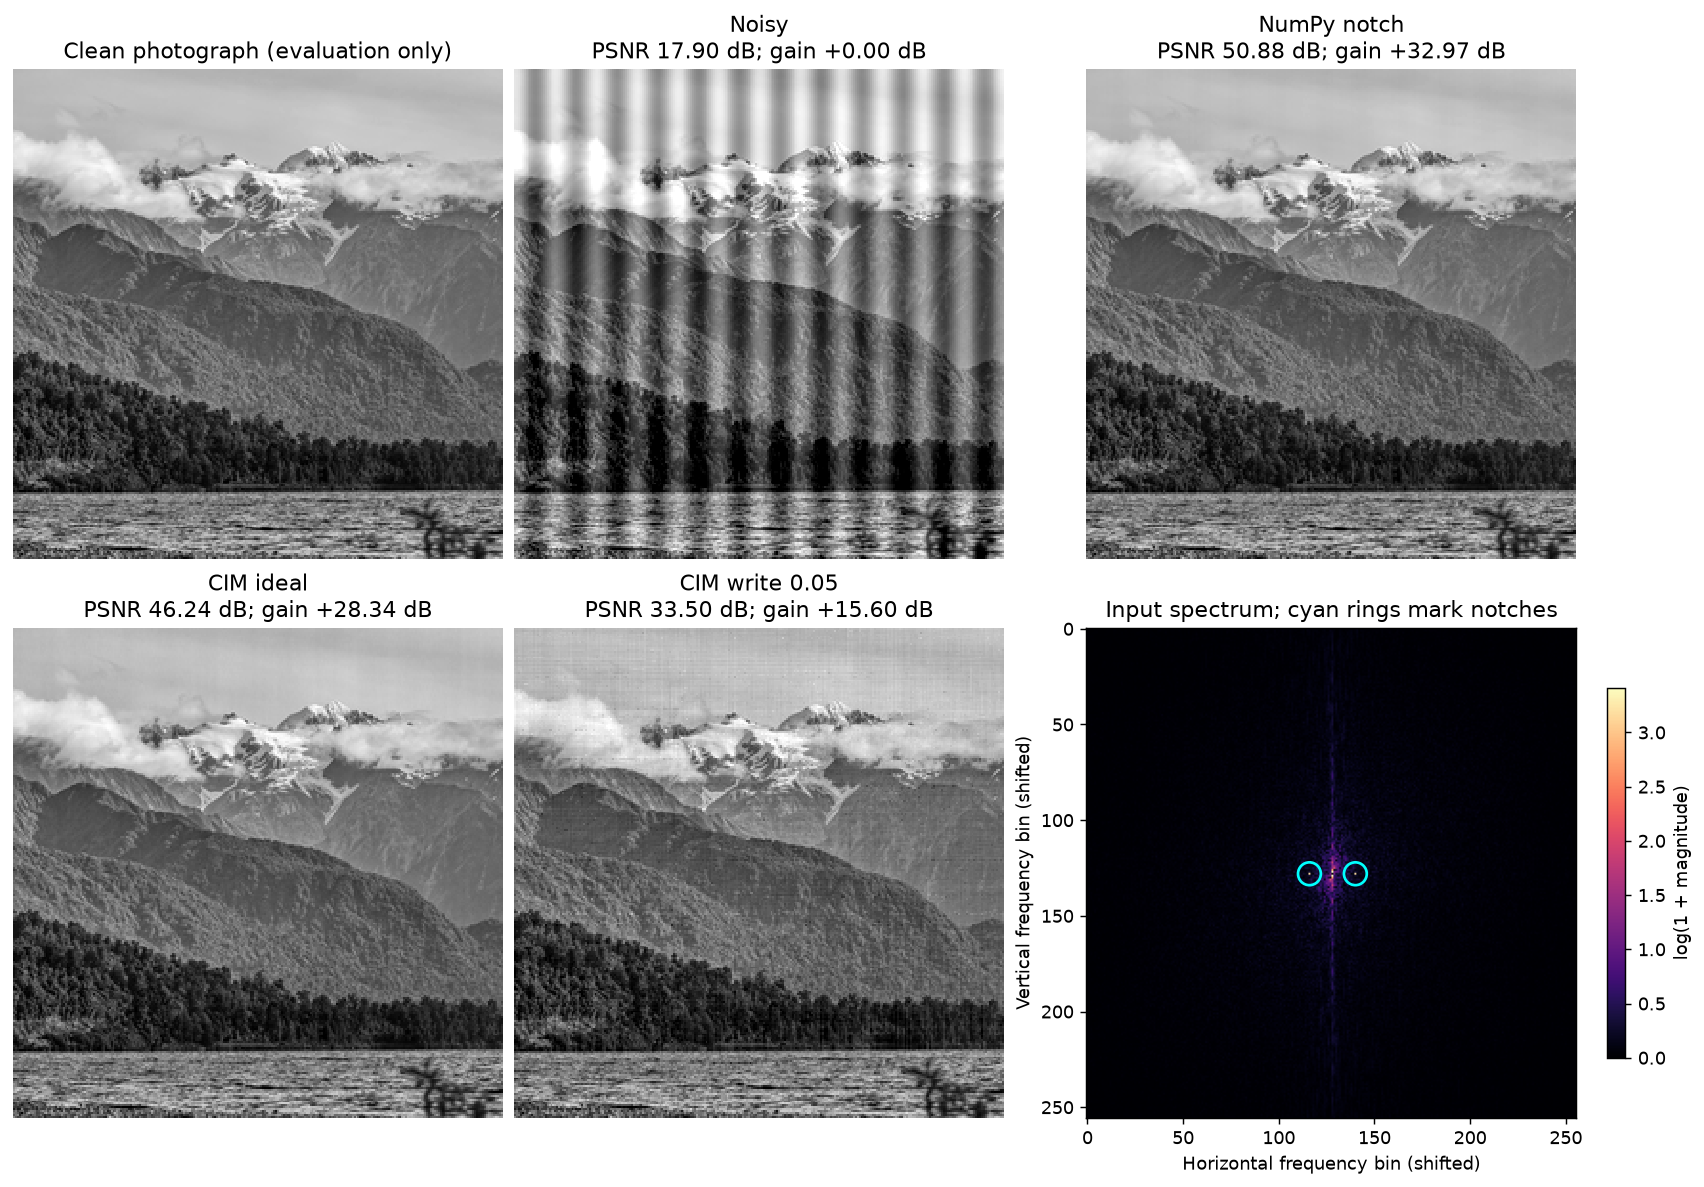

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 9), dpi=130, constrained_layout=True)
panels = axes.ravel()
panels[0].imshow(clean, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
panels[0].set_title("Clean photograph (evaluation only)")
panels[0].axis("off")
for ax, (label, item) in zip(panels[1:5], results.items()):
    ax.imshow(item["image"], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    gain = item["psnr_db"] - results["Noisy"]["psnr_db"]
    ax.set_title(f"{label}\nPSNR {item['psnr_db']:.2f} dB; gain {gain:+.2f} dB")
    ax.axis("off")
response = panels[5].imshow(
    np.log1p(np.abs(np.fft.fftshift(numpy_spectrum))), cmap="magma"
)
panels[5].scatter(
    [SIZE // 2 - STRIPE_CYCLES, SIZE // 2 + STRIPE_CYCLES],
    [SIZE // 2, SIZE // 2], s=160, facecolors="none", edgecolors="cyan", linewidths=1.5,
)
panels[5].set_title("Input spectrum; cyan rings mark notches")
panels[5].set_xlabel("Horizontal frequency bin (shifted)")
panels[5].set_ylabel("Vertical frequency bin (shifted)")
fig.colorbar(response, ax=panels[5], shrink=0.75, label="log(1 + magnitude)")

# Run from this notebook's directory or the repository root.
notebook_dir = Path.cwd()
if not (notebook_dir / "03_dft_image_denoising.ipynb").is_file():
    notebook_dir = notebook_dir / "examples" / "notebooks"
assert (notebook_dir / "03_dft_image_denoising.ipynb").is_file()
asset_dir = notebook_dir / "assets"
asset_dir.mkdir(exist_ok=True)
fig.savefig(asset_dir / "dft_image_denoising.png", dpi=160)
plt.show()

The same executed figure is also saved as a relative PNG asset for notebook viewers that omit rich outputs:

![Clean, striped, NumPy and CIM reconstructions, with the input spectrum and rejected frequencies](assets/dft_image_denoising.png)